In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Robust path resolution (same logic as Phase 0)
DATA_PATH = Path("../data/raw/european_household_energy.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/raw/european_household_energy.csv")

OUTPUT_DIR = Path("../outputs"); OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUTPUT_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR = OUTPUT_DIR / "evaluation_reports"; TAB_DIR.mkdir(parents=True, exist_ok=True)

# Resolve the dataset from common notebook working directories
DATA_PATH = next(
    (
        candidate
        for candidate in [
            DATA_PATH,
            Path("data/raw/european_household_energy.csv"),
            Path("../data/raw/european_household_energy.csv"),
            *(base / "data/raw/european_household_energy.csv"
              for base in [Path.cwd(), *Path.cwd().parents]),
        ]
        if candidate.exists()
    ),
    None,
)

if DATA_PATH is None:
    DATA_PATH = next(
        (path for path in Path.cwd().rglob("european_household_energy.csv")),
        None,
    )

    if DATA_PATH is None:
        raise FileNotFoundError(
            "Could not find 'european_household_energy.csv'. "
            "Place it in a 'data/raw' directory relative to the notebook project "
            f"(current directory: {Path.cwd()})."
        )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}")
sns.set_theme(style="whitegrid", context="notebook")
"Loaded ✅"

Loaded ..\data\raw\european_household_energy.csv


'Loaded ✅'

In [2]:
data_dictionary = pd.DataFrame([
    ("country_code", "str", "ISO-2 country code", "identifier"),
    ("country_iso2", "str", "ISO-2 code (duplicate, 518 NaN for EU27 rows)", "identifier"),
    ("country", "str", "Country name in English", "identifier"),
    ("is_country_group", "bool", "True = EU27 aggregate (exclude from analysis)", "identifier"),
    ("end_use_code", "str", "End-use category code (7 categories)", "category"),
    ("end_use", "str", "End-use label", "category"),
    ("fuel_code", "str", "Fuel category code (14 categories, includes TOTAL)", "category"),
    ("fuel", "str", "Fuel label", "category"),
    ("period", "int64", "Year as integer (duplicate of year)", "temporal"),
    ("date", "str", "ISO date string → convert to datetime in Phase 2", "temporal"),
    ("year", "int64", "Reporting year (2010–2024)", "temporal"),
    ("energy_tj", "float64", "Energy consumption in Terajoules (target)", "target"),
    ("flag", "str", "Quality flag: e=estimated, u=low reliability, NaN=normal", "metadata"),
    ("flag_meaning", "str", "Human-readable meaning of flag", "metadata"),
], columns=["column", "dtype", "description", "role"])

data_dictionary.style.hide(axis="index")

column,dtype,description,role
country_code,str,ISO-2 country code,identifier
country_iso2,str,"ISO-2 code (duplicate, 518 NaN for EU27 rows)",identifier
country,str,Country name in English,identifier
is_country_group,bool,True = EU27 aggregate (exclude from analysis),identifier
end_use_code,str,End-use category code (7 categories),category
end_use,str,End-use label,category
fuel_code,str,"Fuel category code (14 categories, includes TOTAL)",category
fuel,str,Fuel label,category
period,int64,Year as integer (duplicate of year),temporal
date,str,ISO date string → convert to datetime in Phase 2,temporal


In [3]:
real = df[df.is_country_group == False].copy()

# ---- A) Prediction eligibility: (country, year, end_use, fuel) ----
pred_rows = real.groupby(["end_use_code", "fuel_code"]).agg(
    rows=("energy_tj", "size"),
    zeros=("energy_tj", lambda s: (s == 0).sum()),
    positives=("energy_tj", lambda s: (s > 0).sum()),
).reset_index()
pred_rows["zero_pct"] = (pred_rows["zeros"] / pred_rows["rows"] * 100).round(1)
pred_rows["eligible_for_prediction"] = (
    (pred_rows["zero_pct"] < 85)      # drop structural zeros
    & (pred_rows["end_use_code"] != "FC_OTH_HH_E_OE")  # drop other-end-use (88.5% zero)
)

# ---- B) Forecasting eligibility: (country) with continuous series ----
forecast_elig = (
    real[(real.end_use_code == "FC_OTH_HH_E") & (real.fuel_code == "TOTAL")]
    .groupby("country")["year"]
    .agg(min_year="min", max_year="max", n_years="nunique")
)
forecast_elig["expected_years"] = forecast_elig.max_year - forecast_elig.min_year + 1
forecast_elig["is_continuous"] = forecast_elig.n_years == forecast_elig.expected_years
forecast_elig["eligible_for_forecast"] = forecast_elig.is_continuous & (forecast_elig.n_years >= 10)

# ---- C) Clustering eligibility: (country) with usable history ----
cluster_elig = (
    real.groupby("country").agg(
        n_years=("year", "nunique"),
        n_positive_rows=("energy_tj", lambda s: (s > 0).sum()),
    )
)
cluster_elig["eligible_for_clustering"] = (
    (cluster_elig["n_years"] >= 10) & (cluster_elig["n_positive_rows"] >= 20)
)

pd.DataFrame({
    "module": ["Prediction", "Forecasting", "Clustering"],
    "denominator": [
        f"{len(pred_rows)} (end_use × fuel)",
        f"{len(forecast_elig)} (countries)",
        f"{len(cluster_elig)} (countries)",
    ],
    "eligible": [
        f"{pred_rows.eligible_for_prediction.sum()}",
        f"{forecast_elig.eligible_for_forecast.sum()}",
        f"{cluster_elig.eligible_for_clustering.sum()}",
    ],
    "excluded": [
        f"{(~pred_rows.eligible_for_prediction).sum()}",
        f"{(~forecast_elig.eligible_for_forecast).sum()}",
        f"{(~cluster_elig.eligible_for_clustering).sum()}",
    ],
})

,module,denominator,eligible,excluded
0,Prediction,74 (end_use × fuel),50,24
1,Forecasting,39 (countries),30,9
2,Clustering,39 (countries),31,8


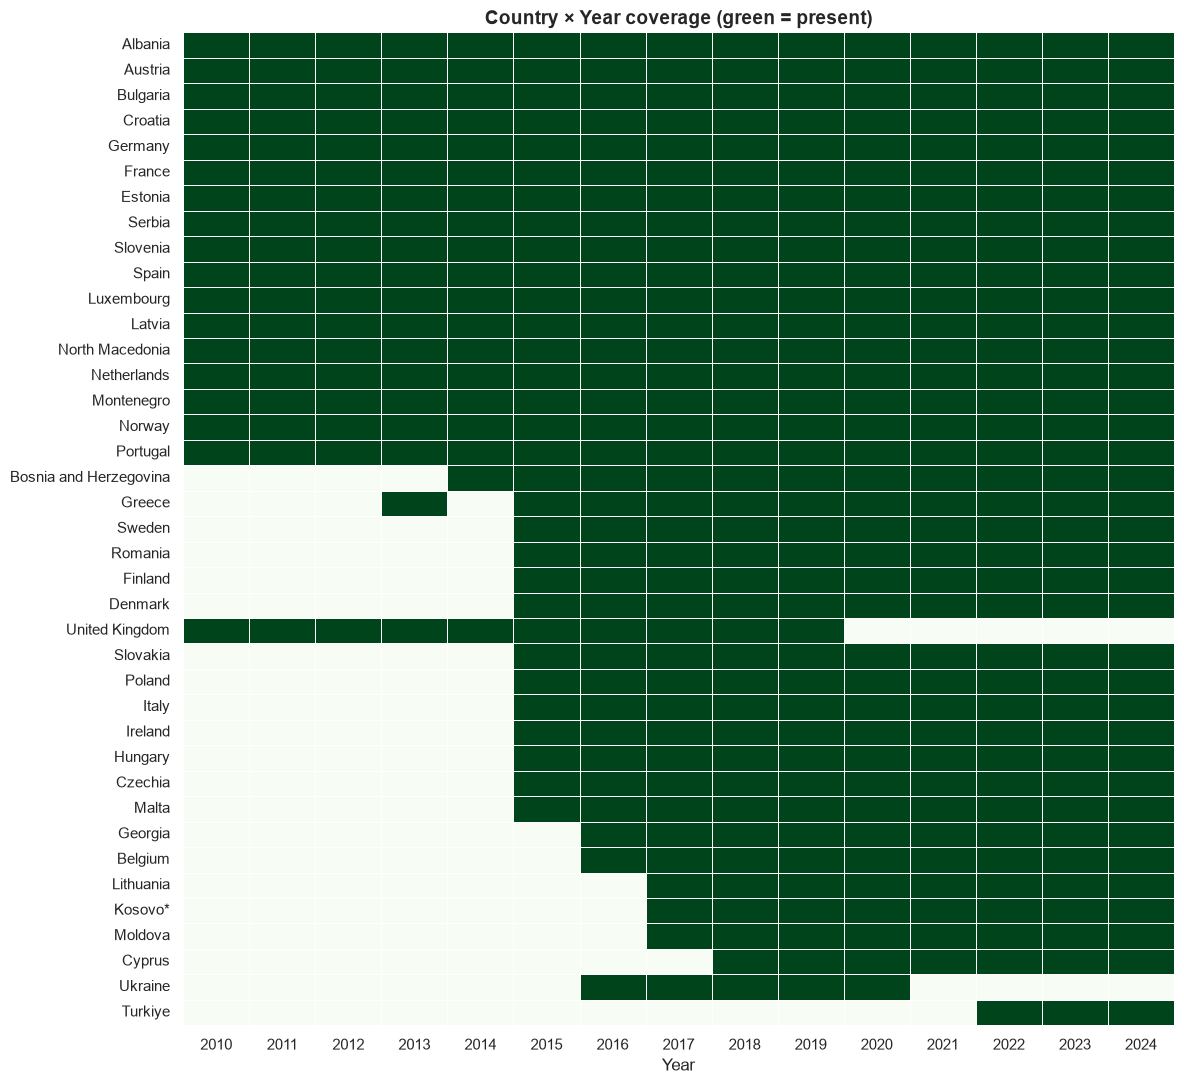

In [4]:
coverage_matrix = (
    real.groupby(["country", "year"])
    .size()
    .unstack(fill_value=0)
    .astype(int)
)
coverage_present = (coverage_matrix > 0).astype(int)

# Order countries by coverage count (most complete on top)
order = coverage_present.sum(axis=1).sort_values(ascending=False).index
coverage_present = coverage_present.loc[order]

fig, ax = plt.subplots(figsize=(12, 11))
sns.heatmap(coverage_present, cmap="Greens", cbar=False, linewidths=0.4, ax=ax)
ax.set_title("Country × Year coverage (green = present)", fontsize=14, fontweight="bold")
ax.set_xlabel("Year"); ax.set_ylabel("")
plt.tight_layout()
fig.savefig(FIG_DIR / "phase1_coverage_heatmap.png", bbox_inches="tight")
plt.show()

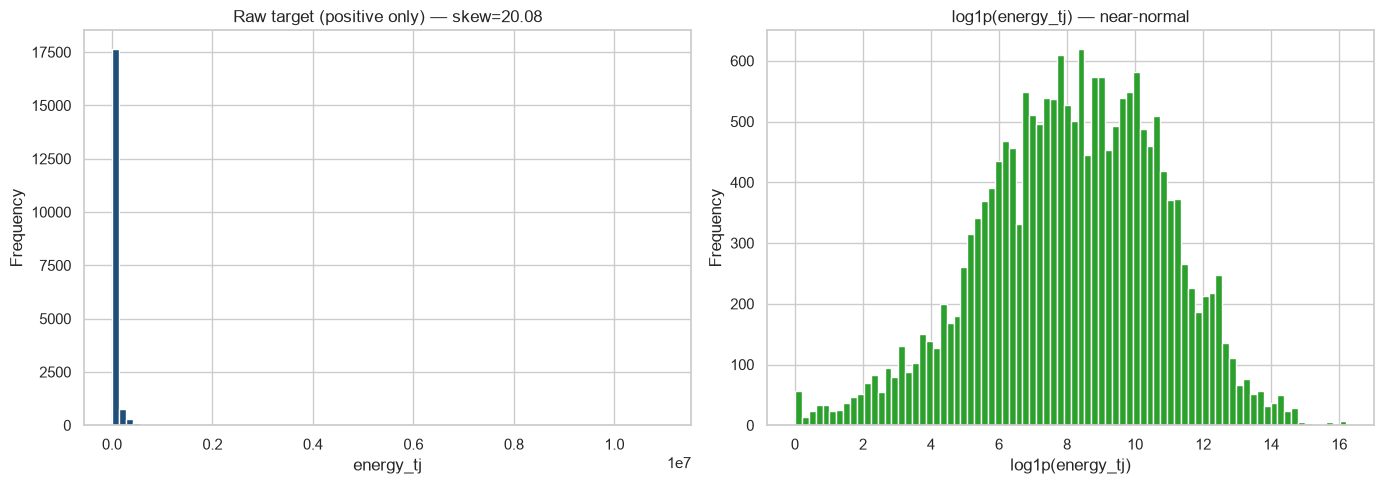

In [5]:
pos = df.loc[df.energy_tj > 0, "energy_tj"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(pos, bins=80, color="#1f4e79")
axes[0].set_title(f"Raw target (positive only) — skew={pos.skew():.2f}")
axes[0].set_xlabel("energy_tj"); axes[0].set_ylabel("Frequency")

axes[1].hist(np.log1p(pos), bins=80, color="#2ca02c")
axes[1].set_title("log1p(energy_tj) — near-normal")
axes[1].set_xlabel("log1p(energy_tj)"); axes[1].set_ylabel("Frequency")

plt.tight_layout()
fig.savefig(FIG_DIR / "phase1_target_distribution.png", bbox_inches="tight")
plt.show()

In [6]:
zero_fuel = (
    real.groupby("fuel").agg(
        rows=("energy_tj", "size"),
        zeros=("energy_tj", lambda s: (s == 0).sum()),
    )
    .assign(zero_pct=lambda d: (d["zeros"] / d["rows"] * 100).round(1))
    .sort_values("zero_pct", ascending=False)
)

zero_enduse = (
    real.groupby("end_use").agg(
        rows=("energy_tj", "size"),
        zeros=("energy_tj", lambda s: (s == 0).sum()),
    )
    .assign(zero_pct=lambda d: (d["zeros"] / d["rows"] * 100).round(1))
    .sort_values("zero_pct", ascending=False)
)

pd.concat([
    zero_fuel.rename_axis("category").assign(kind="fuel"),
    zero_enduse.rename_axis("category").assign(kind="end_use"),
]).style.format({"zero_pct": "{:.1f}%"}).background_gradient(subset=["zero_pct"], cmap="Reds")

,rows,zeros,zero_pct,kind
category,,,,
Biogases,2235,2129,95.3%,fuel
Other kerosene,2235,1912,85.5%,fuel
Ambient heat (heat pumps),2235,1557,69.7%,fuel
Solar thermal,2235,1398,62.6%,fuel
Gas oil and diesel oil,2235,1305,58.4%,fuel
Heat,2256,1264,56.0%,fuel
"Solid fossil fuels, peat, peat products, oil shale and oil sands",2260,1146,50.7%,fuel
Liquefied petroleum gases,2259,798,35.3%,fuel
Natural gas,2263,731,32.3%,fuel


In [7]:
split = (
    real.assign(period_group=lambda d: np.where(
        d.year <= 2019, "train_2010-2019",
        np.where(d.year <= 2022, "val_2020-2022", "test_2023-2024")
    ))
    .groupby("period_group")
    .agg(
        rows=("energy_tj", "size"),
        positive=("energy_tj", lambda s: (s > 0).sum()),
        mean_positive=("energy_tj", lambda s: s[s > 0].mean()),
        median_positive=("energy_tj", lambda s: s[s > 0].median()),
    )
)
split["positive_pct"] = (split["positive"] / split["rows"] * 100).round(1)

split.style.format({
    "mean_positive": "{:,.0f}", "median_positive": "{:,.0f}",
    "positive_pct": "{:.1f}%",
})

,rows,positive,mean_positive,median_positive,positive_pct
period_group,,,,,
test_2023-2024,5338,3080,"34,304","3,447",57.7%
train_2010-2019,19980,11011,"43,872","3,836",55.1%
val_2020-2022,8038,4590,"35,462","3,466",57.1%


In [ ]:
data_dictionary.to_csv(TAB_DIR / "phase1_data_dictionary.csv", index=False)
pred_rows.to_csv(TAB_DIR / "phase1_prediction_eligibility.csv", index=False)
forecast_elig.reset_index().to_csv(TAB_DIR / "phase1_forecasting_eligibility.csv", index=False)
cluster_elig.reset_index().to_csv(TAB_DIR / "phase1_clustering_eligibility.csv", index=False)

pd.DataFrame({
    "saved_file": [
        "phase1_data_dictionary.csv",
        "phase1_prediction_eligibility.csv",
        "phase1_forecasting_eligibility.csv",
        "phase1_clustering_eligibility.csv",
    ],
    "rows": [
        len(data_dictionary), len(pred_rows),
        len(forecast_elig), len(cluster_elig),
    ],
})

,saved_file,rows
0,phase1_data_dictionary.csv,14
1,phase1_prediction_eligibility.csv,74
2,phase1_forecasting_eligibility.csv,39
3,phase1_clustering_eligibility.csv,39


: 

# 📋 Phase 1 — Data Understanding Summary

## 1. Dataset shape
- 33,874 rows × 14 columns
- 39 real countries + 1 country group (EU27)
- 15 years (2010–2024)

## 2. Target variable
- `energy_tj` is **right-skewed (skew = 20.08)** → **log1p-transform required**
- 43.5% zeros — must be classified as valid vs structural before modeling

## 3. Coverage
- **17 countries** have full 15-year coverage
- **22 countries** have partial coverage (as low as 3 years)
- **38/39 countries** have continuous TOTAL series
- **30 countries** meet the forecasting gate (continuous + ≥10 years)

## 4. Structural zeros (excluded from prediction)
| Fuel | Zero % | Decision |
|---|---|---|
| Biogases | 95.3% | ❌ Drop |
| Other kerosene | 85.5% | ❌ Drop |
| Other end-use | 88.5% | ❌ Drop |

## 5. End-use × Fuel combos
- 74/98 combinations present
- After structural-zero removal: **~70 combos** usable for prediction

## 6. Chronological split (locked)
| Set | Years | Rows | Positive % |
|---|---|---|---|
| Train | 2010–2019 | 19,980 | 55.1% |
| Val | 2020–2022 | 8,038 | 57.1% |
| Test | 2023–2024 | 5,338 | 57.7% |

✅ Balanced distribution across splits → no distribution shift to fix.

## 7. Data quality flags
- 70 rows flagged "estimated" (0.2%)
- 1 row flagged "low reliability"
- **Decision:** keep all, but note in documentation.

## 8. Locked modeling decisions
| Decision | Value |
|---|---|
| Prediction level | country × year × end_use × fuel |
| Target transform | log1p |
| Structural zeros dropped | Biogases, Other kerosene |
| End-use dropped | Other end-use (OE) |
| Split | Chronological 2019 / 2022 |
| Forecasting scope | 30 countries (continuous + ≥10 yrs) |
| Clustering scope | countries with ≥10 yrs and ≥20 positive rows |
| Benchmark | EU27 aggregate (comparison only, never training) |

## 9. What Phase 2 will build
- `panel_level.csv` — filtered to eligible (end_use, fuel) combos
- `country_total.csv` — TOTAL series for forecasting
- `country_profile.csv` — per-country features for clustering
- `data_preparation_log.csv` — full audit

---
**Status:** Phase 1 complete. Ready for Phase 2 — Data Preparation.